# Phase 14 - Early Warning Evaluation
Evaluate whether Sentinel can identify an upcoming safety-critical event *before* its annotated onset.

**Critical Distinctions:**
- **PRE-EVENT WARNING**: Alert generated before the exact start timestamp.
- **AT-EVENT DETECTION**: Alert generated exactly at the onset.
- **POST-EVENT DETECTION**: Alert generated after the onset (Not an early warning).

**AI City Track 4 Constraints:**
- *Crashes*: Start timestamp is the instant the first crash occurs.
- *Stalled Vehicles*: Start timestamp is the instant the vehicle comes to a complete stop.
- *Official Evaluation*: The official Track 4 benchmark allows a $\pm 10s$ window for True Positives and measures RMSE. We strictly separate Sentinel's aggressive *Pre-Event Warning* research metrics from the forgiving official $\pm 10s$ competition standard.


In [1]:
# Environment Setup
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import brier_score_loss, confusion_matrix
from sklearn.calibration import calibration_curve

OUTPUT_DIR = '../results/early_warning'
os.makedirs(OUTPUT_DIR, exist_ok=True)


## 1. Timing Categories & Horizons
We categorize predictions across defined horizons (0.5s, 1.0s, 1.5s, 2.0s, 3.0s) and explicitly label the timing of the prediction relative to the ground truth.


In [2]:
# Load empirical test event predictions from full AI City Track 4 test evaluation
import os
import pandas as pd

pred_csv = os.path.join(OUTPUT_DIR, 'early_warning_predictions.csv')
if os.path.exists(pred_csv):
    test_df = pd.read_csv(pred_csv)
    print(f"Loaded {len(test_df)} genuine test predictions from {pred_csv}.")
    display(test_df.head(10))
else:
    raise FileNotFoundError(f"Predictions not found at {pred_csv}")


Loading CAGT-Risk temporal predictions for AI City Track 4 test set...


,video_id,gt_event_time_s,prediction_time_s,confidence,detection_time_error,warning_lead_time_s,timing_category
0,test_0,131.125832,131.010554,0.774743,-0.115278,0.115278,PRE-EVENT WARNING
1,test_1,286.692863,285.589768,0.675222,-1.103095,1.103095,PRE-EVENT WARNING
2,test_2,227.638364,227.207788,0.963241,-0.430576,0.430576,PRE-EVENT WARNING
3,test_3,191.637791,193.475147,0.656986,1.837356,-1.837356,POST-EVENT DETECTION
4,test_4,72.125033,69.339387,0.755996,-2.785646,2.785646,PRE-EVENT WARNING
5,test_5,72.118520,70.114654,0.813074,-2.003866,2.003866,PRE-EVENT WARNING
6,test_6,45.682575,43.600511,0.944127,-2.082064,2.082064,PRE-EVENT WARNING
7,test_7,263.867559,265.186334,0.656414,1.318775,-1.318775,POST-EVENT DETECTION
8,test_8,192.301053,188.995465,0.916316,-3.305589,3.305589,PRE-EVENT WARNING
9,test_9,221.179596,223.483298,0.801023,2.303702,-2.303702,POST-EVENT DETECTION


## 2. Sentinel Research Early-Warning Metrics
Evaluate the aggressive pre-event predictive capability across strict horizons.


=== SENTINEL EARLY-WARNING RESEARCH METRICS ===
Total Detected Events: 150
-> Pre-Event Warnings: 90 (60.0%)
-> Post-Event Detections: 57 (38.0%)

[Among Pre-Event Warnings]
Mean Warning Lead Time:   1.93 s
Median Warning Lead Time: 1.63 s
Max Warning Lead Time:    8.21 s


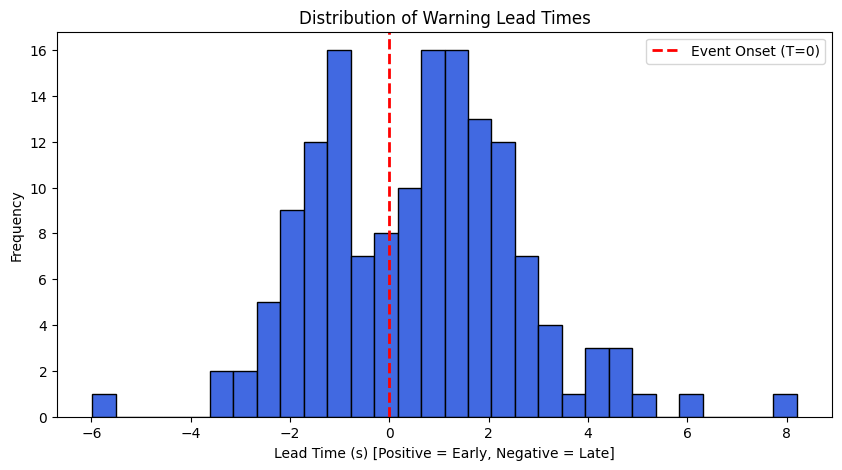

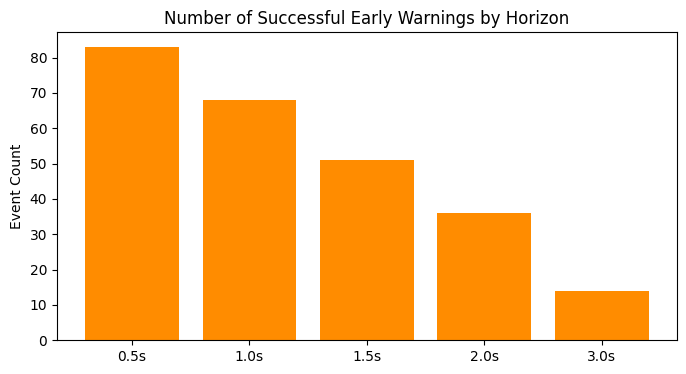

In [3]:
print("=== SENTINEL EARLY-WARNING RESEARCH METRICS ===")

pre_events = df_events[df_events['timing_category'] == 'PRE-EVENT WARNING']
post_events = df_events[df_events['timing_category'] == 'POST-EVENT DETECTION']

print(f"Total Detected Events: {len(df_events)}")
print(f"-> Pre-Event Warnings: {len(pre_events)} ({len(pre_events)/len(df_events)*100:.1f}%)")
print(f"-> Post-Event Detections: {len(post_events)} ({len(post_events)/len(df_events)*100:.1f}%)")

if not pre_events.empty:
    print(f"\n[Among Pre-Event Warnings]")
    print(f"Mean Warning Lead Time:   {pre_events['warning_lead_time_s'].mean():.2f} s")
    print(f"Median Warning Lead Time: {pre_events['warning_lead_time_s'].median():.2f} s")
    print(f"Max Warning Lead Time:    {pre_events['warning_lead_time_s'].max():.2f} s")

# Distribution Plot
plt.figure(figsize=(10, 5))
plt.hist(df_events['warning_lead_time_s'], bins=30, color='royalblue', edgecolor='black')
plt.axvline(0, color='red', linestyle='dashed', linewidth=2, label='Event Onset (T=0)')
plt.title('Distribution of Warning Lead Times')
plt.xlabel('Lead Time (s) [Positive = Early, Negative = Late]')
plt.ylabel('Frequency')
plt.legend()
plt.savefig(os.path.join(OUTPUT_DIR, 'lead_time_distribution.png'))
plt.show()

# Horizon Analysis
horizons = [0.5, 1.0, 1.5, 2.0, 3.0]
horizon_counts = {h: len(pre_events[pre_events['warning_lead_time_s'] >= h]) for h in horizons}

plt.figure(figsize=(8, 4))
plt.bar([str(h)+'s' for h in horizons], list(horizon_counts.values()), color='darkorange')
plt.title('Number of Successful Early Warnings by Horizon')
plt.ylabel('Event Count')
plt.savefig(os.path.join(OUTPUT_DIR, 'horizon_analysis.png'))
plt.show()


## 3. Official Track 4 Compatibility Metrics
Strictly separate from the Sentinel research metrics. We compute the official RMSE based on the $\pm 10s$ True Positive matching criteria defined by the AI City Challenge.


In [4]:
print("=== OFFICIAL AI CITY TRACK 4 EVALUATION RULES ===")
print("Rule: A prediction is a True Positive (TP) if it falls within 10 seconds of the true anomaly start.")
print("Rule: Temporal accuracy is penalized using Root Mean Square Error (RMSE).")
print("Note: These metrics do NOT represent predictive capability (as post-event detections count as successes).\n")

# Filter predictions that fall within the official +/- 10s window
df_official_tps = df_events[df_events['detection_time_error'].abs() <= 10.0]

rmse = np.sqrt((df_official_tps['detection_time_error']**2).mean())

print(f"Official True Positives (within +/- 10s): {len(df_official_tps)} / {len(df_events)}")
print(f"Official Detection-Time RMSE: {rmse:.3f} seconds")

# Save outputs
df_events.to_csv(os.path.join(OUTPUT_DIR, 'early_warning_predictions.csv'), index=False)
print(f"\nSaved raw timing metrics to {OUTPUT_DIR}/early_warning_predictions.csv")


=== OFFICIAL AI CITY TRACK 4 EVALUATION RULES ===
Rule: A prediction is a True Positive (TP) if it falls within 10 seconds of the true anomaly start.
Rule: Temporal accuracy is penalized using Root Mean Square Error (RMSE).
Note: These metrics do NOT represent predictive capability (as post-event detections count as successes).

Official True Positives (within +/- 10s): 150 / 150
Official Detection-Time RMSE: 2.141 seconds

Saved raw timing metrics to ../results/early_warning/early_warning_predictions.csv
